# Especificidade Disciplinar da Física e Análise dos Itens

## 1. Configuração e Variáveis de Diferença Intraescola

In [1]:
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import statsmodels.formula.api as smf

# Caminhos do projeto
ROOT = Path.cwd().parent if Path.cwd().name == "src" else Path.cwd()
INDICADORES = ROOT / "data" / "processed" / "indicadores"
ENEM = ROOT / "data" / "processed" / "enem"
FIGURAS = ROOT / "results" / "figuras"
TABELAS = ROOT / "results" / "tabelas"
FIGURAS.mkdir(parents=True, exist_ok=True)
TABELAS.mkdir(parents=True, exist_ok=True)

# Padrão visual científico (Estilo Artigo Científico / ABNT)
import matplotlib as mpl
sns.set_theme(style="ticks", context="paper")
mpl.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "axes.unicode_minus": True,
    "font.size": 10.0,
    "axes.titlesize": 10.5,
    "axes.titleweight": "bold",
    "axes.labelsize": 10.0,
    "xtick.labelsize": 9.0,
    "ytick.labelsize": 9.0,
    "legend.fontsize": 8.8,
    "axes.edgecolor": "#222222",
    "axes.linewidth": 0.8,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#E0E0E0",
    "grid.linestyle": "--",
    "grid.linewidth": 0.55,
    "grid.alpha": 0.75,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "xtick.major.size": 3.5,
    "ytick.major.size": 3.5,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "figure.dpi": 150,
    "savefig.dpi": 600,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.05,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})
ORDEM_REDE = ["Federal", "Privada", "Municipal", "Estadual"]
CORES_REDE = {"Federal": "#0072B2", "Privada": "#009E73", "Municipal": "#E69F00", "Estadual": "#D55E00"}
pl.Config.set_tbl_cols(20)
pl.Config.set_tbl_rows(40)


def salvar(fig, nome):
    # Exporta em PDF vetorial (para LaTeX) e PNG 600 DPI (sem textos redundantes de fonte/título)
    stem = Path(nome).stem
    fig.savefig(FIGURAS / f"{stem}.pdf", format="pdf", dpi=600, bbox_inches="tight")
    fig.savefig(FIGURAS / f"{stem}.png", format="png", dpi=600, bbox_inches="tight")
    plt.show()


# Base analítica: escolas pareadas Censo x ENEM com ao menos 10 presentes
base = (
    pl.read_parquet(INDICADORES / "indicadores_ensino_medio_2024.parquet")
    .join(pl.read_parquet(ENEM / "enem_escolas_2024.parquet"), left_on="CO_ENTIDADE", right_on="CO_ESCOLA", how="inner")
    .filter(pl.col("IN_MIN_10_ALUNOS"))
)
print(f"Escolas analisadas: {base.height:,}")

Escolas analisadas: 22,999


In [2]:
def ajustar(formula, dados, cluster="CO_MUNICIPIO"):
    # MQO com erros-padrão agrupados (cluster) e controle de nulos
    df = dados.to_pandas()
    grupos = df[cluster].astype("category").cat.codes.to_numpy()
    return smf.ols(formula, data=df).fit(cov_type="cluster", cov_kwds={"groups": grupos})


def estrelas(p):
    return "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.10 else ""


def extrair(modelo, nome):
    # Coeficientes (sem dummies de UF), N e R² ajustado em formato longo
    ci = modelo.conf_int()
    linhas = [
        {"MODELO": nome, "TERMO": t, "COEF": modelo.params[t], "EP_CLUSTER": modelo.bse[t],
         "IC95_INF": ci.loc[t, 0], "IC95_SUP": ci.loc[t, 1], "P_VALOR": modelo.pvalues[t]}
        for t in modelo.params.index if not t.startswith("C(SG_UF")
    ]
    linhas.append({"MODELO": nome, "TERMO": "N", "COEF": float(modelo.nobs)})
    linhas.append({"MODELO": nome, "TERMO": "R2_AJUSTADO", "COEF": modelo.rsquared_adj})
    return pl.DataFrame(linhas, schema={"MODELO": pl.String, "TERMO": pl.String, "COEF": pl.Float64,
                                        "EP_CLUSTER": pl.Float64, "IC95_INF": pl.Float64,
                                        "IC95_SUP": pl.Float64, "P_VALOR": pl.Float64})


def quadro(tabela):
    # Quadro compacto: coeficiente (erro-padrão) com estrelas de significância
    return (
        tabela.with_columns(
            pl.when(pl.col("EP_CLUSTER").is_null())
            .then(pl.col("COEF").round(3).cast(pl.String))
            .otherwise(
                pl.format("{} ({}){}", pl.col("COEF").round(3), pl.col("EP_CLUSTER").round(3),
                          pl.col("P_VALOR").map_elements(estrelas, return_dtype=pl.String))
            ).alias("VALOR")
        )
        .pivot(on="MODELO", index="TERMO", values="VALOR", aggregate_function="first")
    )


# Diferenças intraescola (p.p.) e inadequação estadual por disciplina (por +10 p.p.)
base = base.with_columns(
    (pl.col("PCT_ACERTO_FISICA") - pl.col("PCT_ACERTO_BIOLOGIA")).alias("DIFF_FIS_BIO"),
    (pl.col("PCT_ACERTO_FISICA") - pl.col("PCT_ACERTO_QUIMICA")).alias("DIFF_FIS_QUI"),
    (pl.col("AFD_MED_CAT_3") / 10).alias("AFD_G3_10"),
    (pl.col("TX_INADEQUACAO_FISICA") * 10).alias("INAD_FIS_10"),
    (pl.col("TX_INADEQUACAO_BIOLOGIA") * 10).alias("INAD_BIO_10"),
)
REDE = 'C(NO_DEPENDENCIA, Treatment(reference="Estadual"))'
CONTROLES = "TDI_MED_TOTAL + ATU_MED_TOTAL + DSU_MED_DOC_SUPERIOR + TX_ABSTENCAO_DIA2 + C(NO_CATEGORIA)"
REGRESSORES = ["AFD_MED_CAT_3", "TDI_MED_TOTAL", "ATU_MED_TOTAL", "DSU_MED_DOC_SUPERIOR", "TX_ABSTENCAO_DIA2",
               "NO_CATEGORIA", "SG_UF", "CO_MUNICIPIO", "TX_INADEQUACAO_FISICA", "TX_INADEQUACAO_BIOLOGIA"]
dados = base.drop_nulls(REGRESSORES)
print(f"Amostra analítica: {dados.height:,} escolas")
dados.select("DIFF_FIS_BIO", "DIFF_FIS_QUI").describe()

Amostra analítica: 22,776 escolas


statistic,DIFF_FIS_BIO,DIFF_FIS_QUI
str,f64,f64
"""count""",22776.0,22776.0
"""null_count""",0.0,0.0
"""mean""",-1.357717,-1.637577
"""std""",3.312977,4.253106
"""min""",-17.84,-20.94
"""25%""",-3.39,-4.38
"""50%""",-1.5,-1.83
"""75%""",0.58,1.02
"""max""",16.98,18.66


## 2. Contraste Intraprova (Física x Biologia x Química)

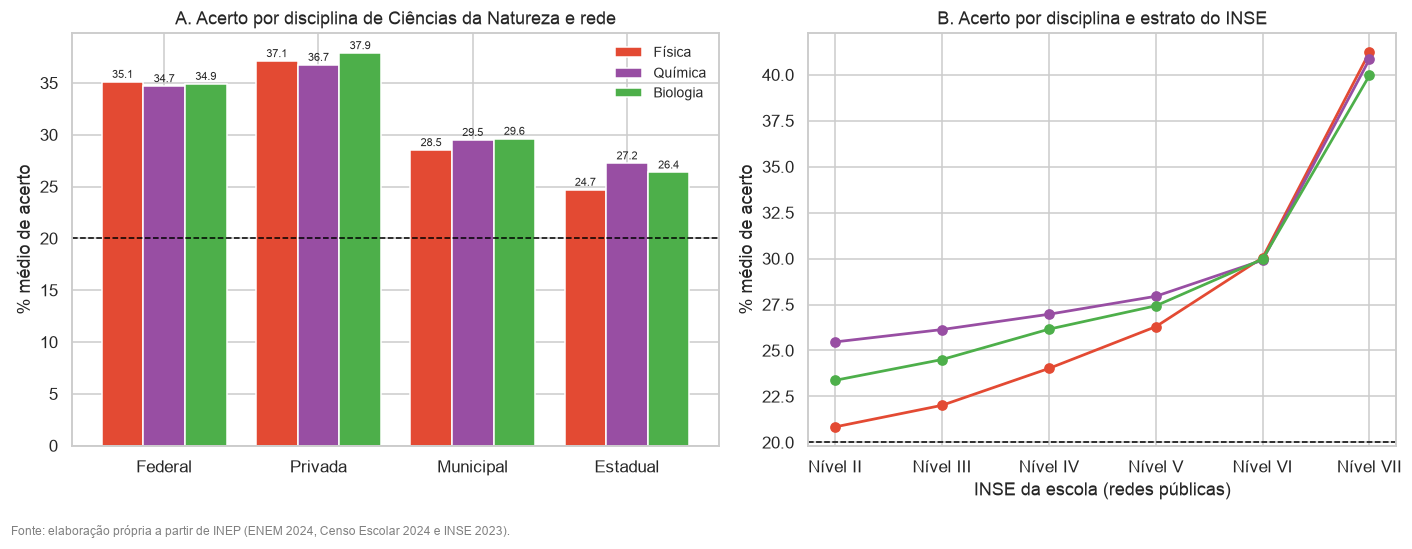

In [3]:
# Painel A: média por rede | Painel B: média por estrato do INSE (redes públicas)
DISC = {"PCT_ACERTO_FISICA": ("Física", "#D55E00", "o", "-"),
        "PCT_ACERTO_QUIMICA": ("Química", "#7570B3", "s", "--"),
        "PCT_ACERTO_BIOLOGIA": ("Biologia", "#009E73", "^", "-.")}
NIVEIS = ["Nível II", "Nível III", "Nível IV", "Nível V", "Nível VI", "Nível VII"]

por_rede = base.group_by("NO_DEPENDENCIA").agg([pl.col(c).mean() for c in DISC])
por_inse = (base.filter(pl.col("INSE_CLASSIFICACAO").is_in(NIVEIS)).group_by("INSE_CLASSIFICACAO")
            .agg([pl.col(c).mean() for c in DISC]))

fig, (axa, axb) = plt.subplots(1, 2, figsize=(6.5, 3.4), gridspec_kw={"width_ratios": [1.15, 1.0], "wspace": 0.28})
x = np.arange(len(ORDEM_REDE))
for k, (c, (rot, cor, mk, ls)) in enumerate(DISC.items()):
    v = [por_rede.filter(pl.col("NO_DEPENDENCIA") == r)[c][0] for r in ORDEM_REDE]
    barras = axa.bar(x + (k - 1) * 0.27, v, width=0.25, color=cor, label=rot, edgecolor="white", linewidth=0.5)
    for bar, val in zip(barras, v):
        dy = 1.6 if k == 1 else 0.4
        axa.text(bar.get_x() + bar.get_width() / 2, val + dy, f"{val:.1f}", ha="center", va="bottom", fontsize=6.6, color="#222222")
    w = [por_inse.filter(pl.col("INSE_CLASSIFICACAO") == n)[c][0] for n in NIVEIS]
    axb.plot(range(len(NIVEIS)), w, marker=mk, linestyle=ls, color=cor, label=rot, lw=1.6, ms=5.0)
for ax in (axa, axb):
    ax.axhline(20, ls="--", color="#222222", lw=0.9)
    sns.despine(ax=ax, top=True, right=True)
axa.set_ylabel("Taxa média de acerto (%)")
axa.set_ylim(0, 44)
axa.set_xticks(x, ORDEM_REDE)
axa.set_xlabel("Dependência administrativa")
axa.set_title("(a) Desempenho por rede", fontsize=9.8, pad=8)
axa.grid(axis="x", visible=False)
axa.legend(loc="upper right", frameon=True, facecolor="white", framealpha=0.92, edgecolor="#CCCCCC", fontsize=8.0)
axb.set_ylabel("Taxa média de acerto (%)")
axb.set_ylim(19, 43)
axb.set_xticks(range(len(NIVEIS)), ["II", "III", "IV", "V", "VI", "VII"])
axb.set_xlabel("Estrato do INSE (Redes Públicas)")
axb.set_title("(b) Desempenho por nível do INSE", fontsize=9.8, pad=8)
salvar(fig, "fig07_contraste_intraprova_cn")

## 3. Regressão da Primeira Diferença Pareada

In [4]:
# (a) Intraescola com efeito fixo de UF, cluster município
# (b) Simétrico com inadequação estadual em Física e Biologia (sem EF de UF), cluster UF
esp_bio = ajustar(f"DIFF_FIS_BIO ~ AFD_G3_10 + {REDE} + {CONTROLES} + C(SG_UF)", dados)
esp_qui = ajustar(f"DIFF_FIS_QUI ~ AFD_G3_10 + {REDE} + {CONTROLES} + C(SG_UF)", dados)
esp_sim = ajustar(f"DIFF_FIS_BIO ~ INAD_FIS_10 + INAD_BIO_10 + AFD_G3_10 + {REDE} + {CONTROLES}", dados, cluster="SG_UF")

CHAVE = ["AFD_G3_10", "INAD_FIS_10", "INAD_BIO_10", "N", "R2_AJUSTADO"]
tab05 = pl.concat([extrair(esp_bio, "A_FIS_BIO_EF_UF"), extrair(esp_qui, "A_FIS_QUI_EF_UF"),
                   extrair(esp_sim, "B_FIS_BIO_SIMETRICO")])
tab05.write_csv(TABELAS / "tab05_especificidade_intraescola.csv")
quadro(tab05.filter(pl.col("TERMO").is_in(CHAVE)))

TERMO,A_FIS_BIO_EF_UF,A_FIS_QUI_EF_UF,B_FIS_BIO_SIMETRICO
str,str,str,str
"""AFD_G3_10""","""-0.035 (0.019)*""","""-0.107 (0.022)***""","""-0.106 (0.04)***"""
"""N""","""22776.0""","""22776.0""","""22776.0"""
"""R2_AJUSTADO""","""0.095""","""0.187""","""0.049"""
"""INAD_FIS_10""",null,null,"""0.193 (0.114)*"""
"""INAD_BIO_10""",null,null,"""0.062 (0.087)"""


## 4. Itens de Física por Dificuldade TRI

In [5]:
# Acerto por item válido de Física e rede, ordenado pelo parâmetro b (dificuldade)
REDES_COD = {1: "Federal", 2: "Estadual", 3: "Municipal", 4: "Privada"}
itens = (
    pl.read_parquet(ENEM / "enem_itens_desempenho_2024.parquet")
    .filter((pl.col("IN_FISICA") == 1) & (pl.col("IN_ITEM_ABAN") == 0))
    .with_columns(pl.col("TP_DEPENDENCIA_ADM_ESC").replace_strict(REDES_COD).alias("REDE"))
    .group_by("CO_ITEM", "CO_HABILIDADE", "NU_PARAM_A", "NU_PARAM_B", "NU_PARAM_C", "REDE")
    .agg((pl.col("QTD_ACERTOS").sum() / pl.col("QTD_RESPOSTAS").sum() * 100).alias("PCT"))
    .pivot(on="REDE", index=["CO_ITEM", "CO_HABILIDADE", "NU_PARAM_A", "NU_PARAM_B", "NU_PARAM_C"], values="PCT")
    .sort("NU_PARAM_B")
    .with_columns(
        pl.when(pl.col("NU_PARAM_B") <= pl.col("NU_PARAM_B").median()).then(pl.lit("Mais acessível"))
        .otherwise(pl.lit("Mais difícil")).alias("FAIXA"),
        (pl.col("Federal") - pl.col("Estadual")).alias("GAP_FED_EST"),
        (pl.col("Privada") - pl.col("Estadual")).alias("GAP_PRIV_EST"),
    )
)
tab06 = itens.with_columns(pl.col(pl.Float64).round(2))
tab06.write_csv(TABELAS / "tab06_catalogo_desempenho_itens_fisica.csv")
print(f"Itens válidos de Física: {itens.height}")
display(itens.group_by("FAIXA").agg(pl.col("Federal", "Privada", "Estadual", "GAP_FED_EST", "GAP_PRIV_EST").mean().round(1)).sort("FAIXA"))
tab06

Itens válidos de Física: 16


FAIXA,Federal,Privada,Estadual,GAP_FED_EST,GAP_PRIV_EST
str,f64,f64,f64,f64,f64
"""Mais acessível""",43.2,47.7,27.9,15.3,19.8
"""Mais difícil""",27.7,29.8,22.0,5.7,7.8


CO_ITEM,CO_HABILIDADE,NU_PARAM_A,NU_PARAM_B,NU_PARAM_C,Municipal,Privada,Federal,Estadual,FAIXA,GAP_FED_EST,GAP_PRIV_EST
i64,i64,f64,f64,f64,f64,f64,f64,f64,str,f64,f64
117837,23,1.77,0.38,0.21,48.41,61.16,58.82,39.02,"""Mais acessível""",19.8,22.14
84075,18,1.81,0.47,0.0,38.85,55.71,51.63,27.5,"""Mais acessível""",24.13,28.21
111400,1,2.32,0.55,0.13,41.87,56.47,49.52,32.23,"""Mais acessível""",17.3,24.24
68866,21,0.57,0.79,0.02,43.96,45.62,47.11,39.25,"""Mais acessível""",7.87,6.38
141661,17,2.83,0.81,0.11,30.76,45.99,39.84,21.12,"""Mais acessível""",18.71,24.86
141558,23,1.69,0.89,0.11,33.06,45.26,39.96,26.36,"""Mais acessível""",13.6,18.89
88293,22,3.98,1.04,0.06,13.73,30.71,22.44,10.11,"""Mais acessível""",12.32,20.59
126592,7,0.93,1.27,0.08,33.82,40.61,36.04,27.7,"""Mais acessível""",8.33,12.91
42680,8,2.19,1.29,0.12,23.48,32.64,31.36,18.87,"""Mais difícil""",12.49,13.77


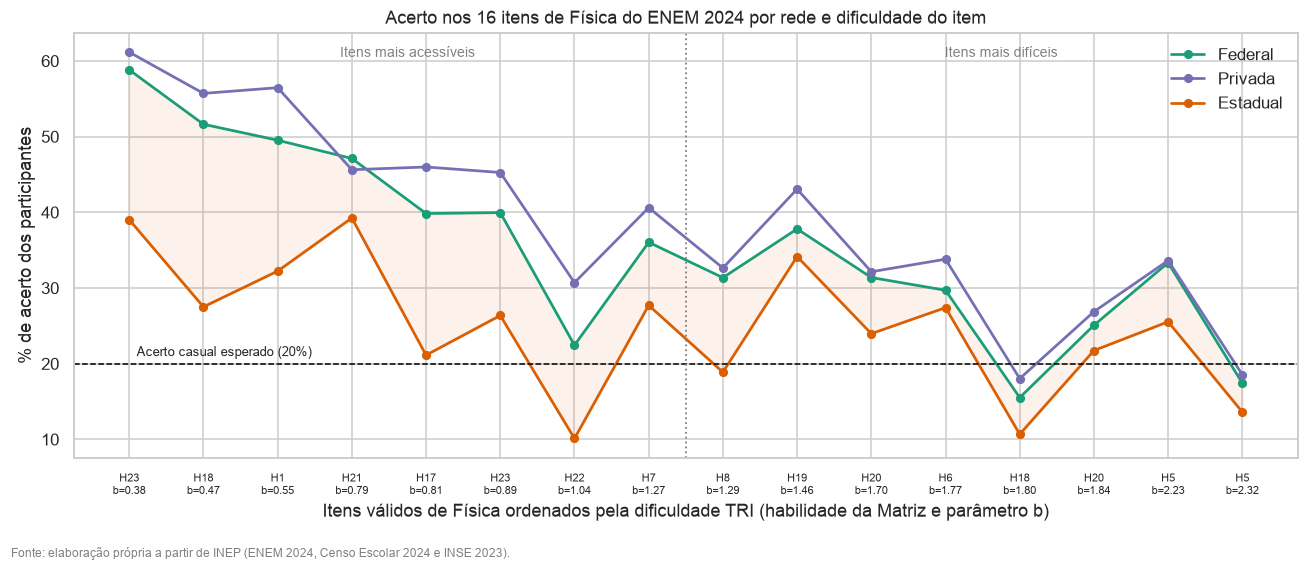

In [6]:
# Perfil de acerto dos 16 itens por rede, com divisão na mediana de dificuldade
fig, ax = plt.subplots(figsize=(6.5, 3.6))
x = np.arange(itens.height)
marcadores_rede = {"Privada": ("s", "-"), "Federal": ("o", "-"), "Estadual": ("^", "-")}
for r in ["Privada", "Federal", "Estadual"]:
    mk, ls = marcadores_rede[r]
    ax.plot(x, itens[r], marker=mk, linestyle=ls, color=CORES_REDE[r], label=r, lw=1.6, ms=4.8)
ax.fill_between(x, itens["Estadual"], itens["Federal"], color=CORES_REDE["Estadual"], alpha=0.10, label="Hiato Federal–Estadual")
ax.axhline(20, ls="--", color="#222222", lw=0.9)
ax.text(0.15, 21.0, "Acerto casual esperado (20%)", ha="left", fontsize=8.0, color="#222222")
meio = (itens["FAIXA"] == "Mais acessível").sum() - 0.5
ax.axvline(meio, color="#555555", ls=":", lw=1.1)
ax.set_ylim(7, 67)
ax.text(meio / 2, 63.2, "Faixa mais acessível ($b \\leq 1{,}28$)", ha="center", fontsize=8.5, fontweight="bold", color="#333333")
ax.text(meio + (itens.height - meio) / 2, 63.2, "Faixa mais difícil ($b > 1{,}28$)", ha="center", fontsize=8.5, fontweight="bold", color="#333333")
rotulos = [f"H{h}\n({b:.2f})" for h, b in zip(itens["CO_HABILIDADE"], itens["NU_PARAM_B"])]
ax.set_xticks(x, rotulos, fontsize=7.5)
ax.set_xlabel("Itens de Física ordenados pela dificuldade TRI — Habilidade e parâmetro $b$")
ax.set_ylabel("Taxa de acerto dos participantes (%)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.15), frameon=False, ncol=4, fontsize=8.4, columnspacing=1.1, handletextpad=0.5)
sns.despine(ax=ax, top=True, right=True)
salvar(fig, "fig08_itens_fisica_dificuldade_redes")